# 05. Model comparison (Consistency)

**Goal.** Compare Ridge, Random Forest and Gradient Boosting (tuned in notebook 04) with each other and with the baselines on
**validation data only**, and apply the protocol's rule for whether a complex model replaces Ridge. The outer test groups are not used.

**Removing the tuning advantage.** For each held-out validation group, the settings are chosen using **only the other three** validation
groups of the same outer fold, then scored on the held-out one. Every number is therefore free of selection bias.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="consistency", title="Consistency", folder=Path(".").resolve(), dataset_file="consistency_dataset.csv", label="rater_consistency", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')]
VARIANTS = {'proposal 4': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')], 'proposal 4 + no-activity flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_no_activity', 'raw')], 'proposal 4 + bimodal flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_bimodal', 'raw')], 'proposal 4 + first active day': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_first_active_day', 'raw')], '3 features (no CV)': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus')], 'AWR + 1-DC': [('C_AWR', 'raw'), ('C_DC', 'one_minus')], 'AWR only': [('C_AWR', 'raw')], 'commits (log) + AWR': [('E_CC', 'log'), ('C_AWR', 'raw')]}
FEATURES = ['C_AWR', 'C_DC', 'C_LI_norm', 'C_CV_norm']
ZERO_RULE_OK = True
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

splits = pd.read_csv(F.splits)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
tune = pd.read_csv(F.results / "tuning_results.csv")
SEEDS = [SEED + i for i in range(5)]
choice03 = json.loads((F.results / "preprocessing_choice.json").read_text())
SETS = []
for name, base, flags in [('proposal 4', 'proposal 4', {}), ('proposal 4, inactive = missing', 'proposal 4', {'nan_inactive': True})]:
    SETS.append((name, VARIANTS.get(base, PROPOSAL), flags))
if all(VARIANTS[choice03["variant"]] != s[1] or s[2] for s in SETS):
    SETS.append(("chosen in notebook 03: " + choice03["variant"], VARIANTS[choice03["variant"]], {"zero_rule": choice03["zero_rule"]}))
SET_NAMES = [s[0] for s in SETS]
assert set(SET_NAMES) == set(tune.feature_set.unique()), (SET_NAMES, tune.feature_set.unique())
print(environment(F))
print(SET_NAMES)

Consistency (744, 25)
{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': 'a46a109a5a5c', 'splits_hash': 'b5793a57b501'}
['proposal 4', 'proposal 4, inactive = missing', 'chosen in notebook 03: 3 features (no CV)']


## 1. Selecting the settings without selection bias

In [2]:
def complexity(row):
    p = json.loads(row.params)
    label_rank = LABEL_SOURCES.index(row.label_source) + (0.5 if row.weight != 1.0 else 0)
    if row.model == "Ridge":
        return (label_rank, -p["alpha"])
    if row.model == "Random Forest":
        return (label_rank, p["n_estimators"] * (p["max_depth"] or 10))
    return (label_rank, p["max_iter"] * (p["max_depth"] or 6) * p["learning_rate"] + (0 if p["monotonic"] else 0.001))


def choose(model, fs, outer, held):
    g = tune[(tune.model == model) & (tune.feature_set == fs) & (tune.outer_test == outer) & (tune.inner_val != held)]
    s = (g.groupby("config_id").agg(MAE=("MAE", "mean"), SE=("MAE", lambda x: x.std(ddof=1) / np.sqrt(len(x))), label_source=("label_source", "first"),
                                    weight=("weight", "first"), params=("params", "first"), model=("model", "first")).reset_index())
    best = s.loc[s.MAE.idxmin()]
    near = s[s.MAE <= best.MAE + best.SE].copy()
    near["c"] = near.apply(complexity, axis=1)
    return near.sort_values("c").iloc[0]


def featurize(frame, fs):
    name, spec, flags = fs
    X = design(frame, spec)
    if flags.get("nan_inactive"):
        X[frame[ACT].to_numpy() == 0, :] = np.nan
    return X


_cache = {}


def get_data(ci, fs_i, label_source, weight):
    key = (ci, fs_i, label_source, weight)
    if key not in _cache:
        test, val, roles = combos[ci]
        fs = SETS[fs_i]
        X, y, w, ids = training_set(d, roles, lambda f: featurize(f, fs), LABEL, PROPOSAL, label_source, weight)
        if fs[2].get("zero_rule"):
            keep = d.loc[ids, ACT].to_numpy() > 0
            X, y, w = X[keep], y[keep], w[keep]
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        _cache[key] = (X, y, w, featurize(v, fs), v[LABEL].to_numpy(), v[ACT].to_numpy(), v.record_id.to_numpy(), v.group.to_numpy())
    return _cache[key]


import time

rows, start = [], time.time()
for model in ("Ridge", "Random Forest", "Gradient Boosting"):
    for fs_i, fs in enumerate(SETS):
        zero_rule = fs[2].get("zero_rule")
        for ci, (test, val, roles) in enumerate(combos):
            pk = choose(model, fs[0], test, val)
            X, y, w, Xv, yv, act, rid, grp = get_data(ci, fs_i, pk.label_source, pk.weight)
            for seed in (SEEDS if model != "Ridge" else SEEDS[:1]):
                m = make_model(model, json.loads(pk.params), X.shape[1])
                if model != "Ridge":
                    m.set_params(random_state=seed)
                m = fit_model(m, model, X, y, w)
                p = np.clip(m.predict(Xv), 0, 1)
                if zero_rule:
                    p = np.where(act == 0, 0.0, p)
                rows += [(f"{model} | {fs[0]}", model, fs[0], test, val, seed, r, g, yy, pp, a, pk.label_source, pk.weight)
                         for r, g, yy, pp, a in zip(rid, grp, yv, p, act)]
    print(f"{model}: {time.time() - start:.0f}s")
tuned = pd.DataFrame(rows, columns=["name", "model", "feature_set", "outer_test", "inner_val", "seed", "record_id", "group", "y", "pred", "activity", "label_source", "weight"])
tuned.to_csv(F.results / "comparison_tuned_predictions.csv", index=False)
print(len(tuned), "predictions")

Ridge: 9s


Random Forest: 99s


Gradient Boosting: 117s
2640 predictions


## 2. Every model side by side

Tuned models use the average over seeds. Baselines come from notebook 02 (untuned).

In [3]:
base = pd.read_csv(F.results / "baseline_validation_predictions.csv")
base = base[base.model != "median"].rename(columns={"model": "name"}).assign(model="baseline", feature_set="", seed=0)
avg = (tuned.groupby(["name", "model", "feature_set", "outer_test", "inner_val", "record_id", "group"])
       .agg(y=("y", "first"), pred=("pred", "mean"), activity=("activity", "first")).reset_index().assign(seed=0))
cols = ["name", "model", "feature_set", "outer_test", "inner_val", "record_id", "group", "y", "pred", "activity", "seed"]
allp = pd.concat([avg[cols], base[cols]], ignore_index=True)
BASELINE_NAMES = sorted(base.name.unique())
print(allp.groupby("name").size().to_string())

name
1 - deadline share (linear)                                      80
1 - deadline share (linear) + zero rule                          80
Gradient Boosting | chosen in notebook 03: 3 features (no CV)    80
Gradient Boosting | proposal 4                                   80
Gradient Boosting | proposal 4, inactive = missing               80
Random Forest | chosen in notebook 03: 3 features (no CV)        80
Random Forest | proposal 4                                       80
Random Forest | proposal 4, inactive = missing                   80
Ridge | chosen in notebook 03: 3 features (no CV)                80
Ridge | proposal 4                                               80
Ridge | proposal 4, inactive = missing                           80
active days (AWR, linear)                                        80
active days (AWR, linear) + zero rule                            80
commits (log, linear)                                            80
commits (log, linear) + zero rule          

## 3. Results (validation, pooled over 20 combinations; intervals resample whole groups)

In [4]:
table = []
for name, g in allp.groupby("name"):
    m = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=1000)
    a = g[g.activity > 0]
    table.append({"model": name, "MAE": m["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": m["RMSE"], "bias": m["bias"], "Pearson": m["pearson"],
                  "Spearman": m["spearman"], "R2": m["R2"], "CCC": m["CCC"], "calib slope": m["calib_slope"], "band exact": m["band_exact"],
                  "band within 1": m["band_within_1"], "MAE active": float(np.abs(a.pred - a.y).mean())})
results = pd.DataFrame(table).set_index("model").sort_values("MAE")
results.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,CCC,calib slope,band exact,band within 1,MAE active
model,,,,,,,,,,,,
ridge (4 proposal features) + zero rule,0.066,0.043-0.079,0.093,0.016,0.909,0.850,0.820,0.897,1.051,0.812,1.000,0.078
ridge (4 proposal features),0.067,0.043-0.079,0.093,0.016,0.910,0.850,0.820,0.897,1.052,0.812,1.000,0.078
Ridge | proposal 4,0.075,0.047-0.088,0.102,0.004,0.902,0.846,0.783,0.858,1.243,0.800,1.000,0.088
"Random Forest | proposal 4, inactive = missing",0.081,0.048-0.099,0.112,0.007,0.865,0.797,0.737,0.833,1.137,0.775,1.000,0.095
"active days (AWR, linear) + zero rule",0.084,0.039-0.130,0.120,0.021,0.871,0.828,0.700,0.864,0.795,0.850,1.000,0.099
"Ridge | proposal 4, inactive = missing",0.086,0.079-0.091,0.113,0.023,0.866,0.748,0.733,0.837,1.094,0.750,1.000,0.085
"active days (AWR, linear)",0.087,0.045-0.130,0.120,0.023,0.869,0.827,0.698,0.862,0.802,0.850,1.000,0.099
Random Forest | proposal 4,0.088,0.056-0.116,0.120,-0.001,0.848,0.786,0.697,0.796,1.213,0.762,1.000,0.101
Ridge | chosen in notebook 03: 3 features (no CV),0.090,0.057-0.103,0.117,0.008,0.852,0.804,0.714,0.817,1.134,0.700,1.000,0.105


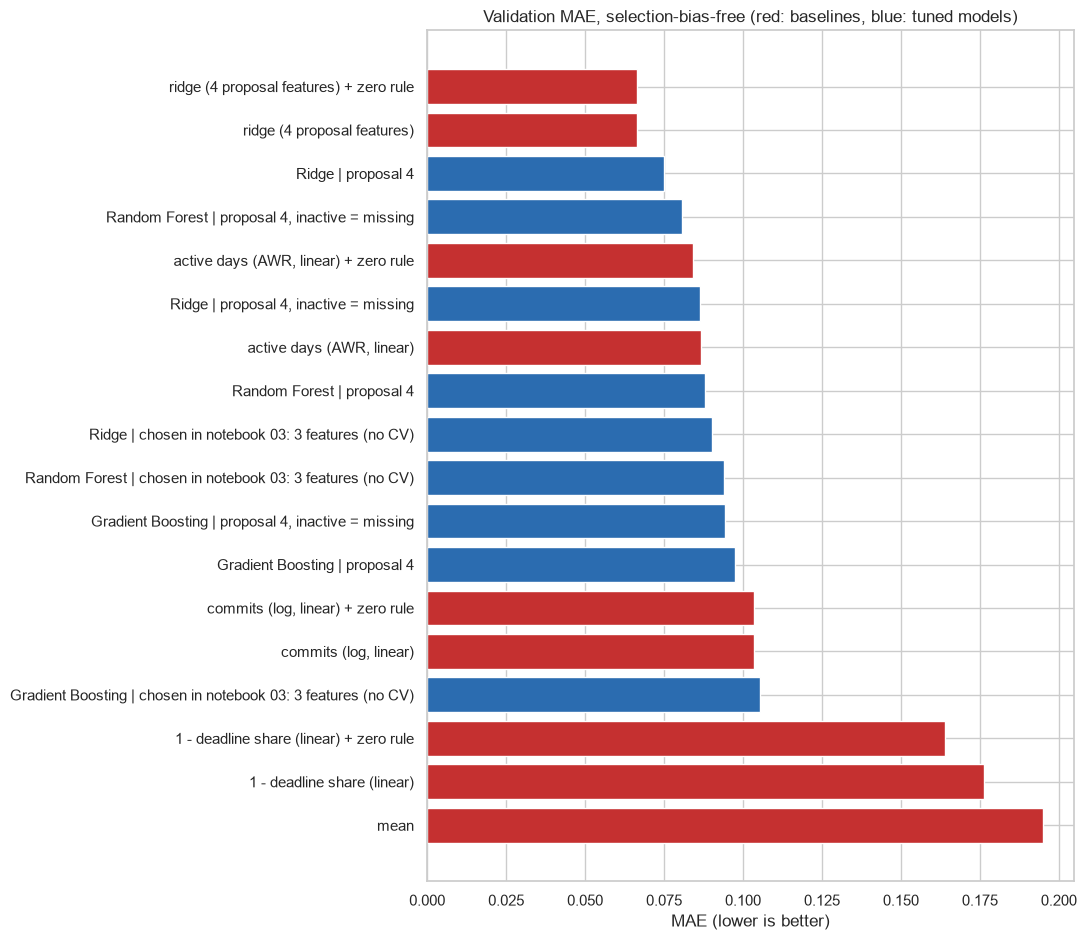

In [5]:
fig, ax = plt.subplots(figsize=(11, 0.42 * len(results) + 2))
ax.barh(results.index, results.MAE, color=["#c53030" if i in BASELINE_NAMES else "#2b6cb0" for i in results.index])
ax.invert_yaxis()
ax.set(title="Validation MAE, selection-bias-free (red: baselines, blue: tuned models)", xlabel="MAE (lower is better)")
plt.tight_layout()
plt.show()

## 4. Seed stability (forest and boosting)

In [6]:
seed_mae = (tuned[tuned.model != "Ridge"].assign(err=lambda x: (x.pred - x.y).abs()).groupby(["name", "seed"]).err.mean().unstack("seed"))
seed_mae["mean"], seed_mae["std over seeds"] = seed_mae.mean(axis=1), seed_mae.std(axis=1)
seed_mae.round(4)

seed,20261018,20261019,20261020,20261021,20261022,mean,std over seeds
name,,,,,,,
Gradient Boosting | chosen in notebook 03: 3 features (no CV),0.1055,0.1055,0.1055,0.1055,0.1055,0.1055,0.0000
Gradient Boosting | proposal 4,0.0975,0.0975,0.0975,0.0975,0.0975,0.0975,0.0000
"Gradient Boosting | proposal 4, inactive = missing",0.0942,0.0942,0.0942,0.0942,0.0942,0.0942,0.0000
Random Forest | chosen in notebook 03: 3 features (no CV),0.0952,0.0941,0.0926,0.0959,0.0932,0.0942,0.0014
Random Forest | proposal 4,0.0872,0.0887,0.0880,0.0873,0.0885,0.0880,0.0007
"Random Forest | proposal 4, inactive = missing",0.0805,0.0816,0.0800,0.0805,0.0808,0.0807,0.0006


## 5. Per-fold results

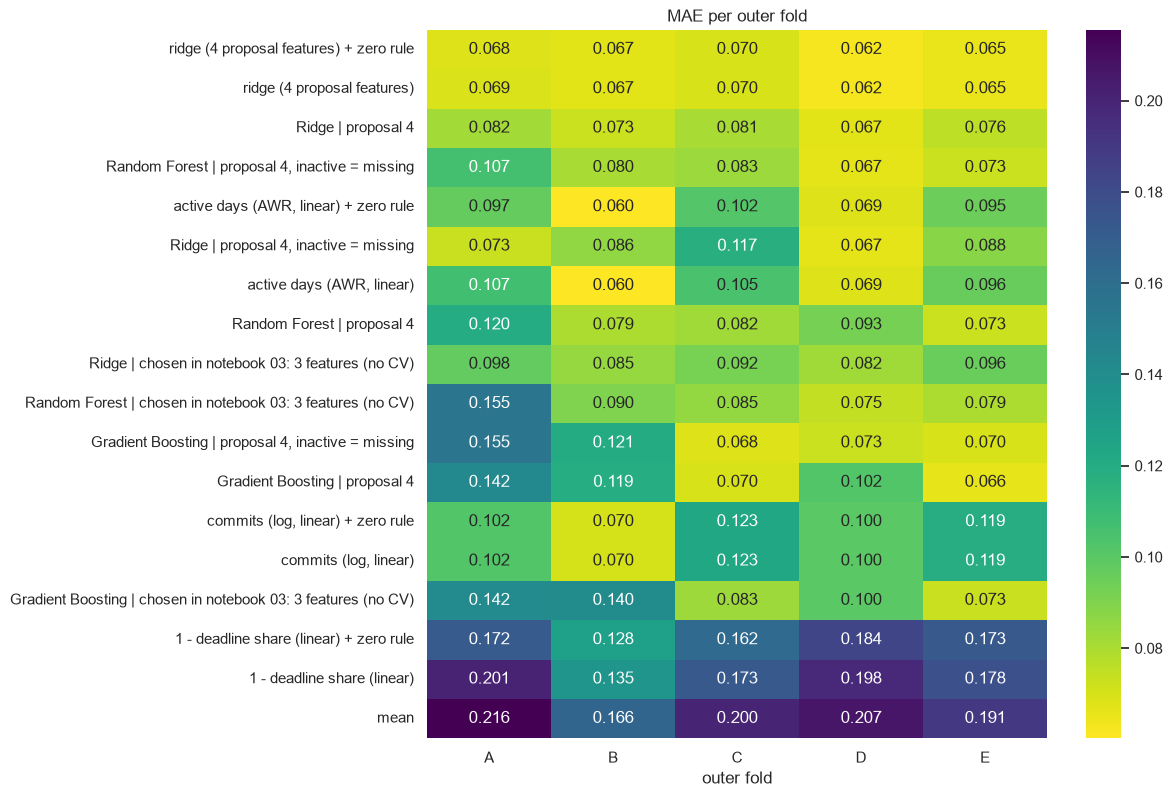

outer_test,A,B,C,D,E,mean,std over folds
model,,,,,,,
ridge (4 proposal features) + zero rule,0.068,0.067,0.070,0.062,0.065,0.067,0.003
ridge (4 proposal features),0.069,0.067,0.070,0.062,0.065,0.067,0.003
Ridge | proposal 4,0.082,0.073,0.081,0.067,0.076,0.075,0.006
"Random Forest | proposal 4, inactive = missing",0.107,0.080,0.083,0.067,0.073,0.082,0.015
"active days (AWR, linear) + zero rule",0.097,0.060,0.102,0.069,0.095,0.085,0.019
"Ridge | proposal 4, inactive = missing",0.073,0.086,0.117,0.067,0.088,0.086,0.020
"active days (AWR, linear)",0.107,0.060,0.105,0.069,0.096,0.087,0.022
Random Forest | proposal 4,0.120,0.079,0.082,0.093,0.073,0.089,0.018
Ridge | chosen in notebook 03: 3 features (no CV),0.098,0.085,0.092,0.082,0.096,0.090,0.007


In [7]:
fold = allp.assign(err=lambda x: (x.pred - x.y).abs()).groupby(["name", "outer_test"]).err.mean().unstack("outer_test")
fold["mean"], fold["std over folds"] = fold.mean(axis=1), fold.std(axis=1)
fig, ax = plt.subplots(figsize=(10, 0.4 * len(fold) + 2))
sns.heatmap(fold.drop(columns=["mean", "std over folds"]).loc[results.index], annot=True, fmt=".3f", cmap="viridis_r", ax=ax)
ax.set(title="MAE per outer fold", xlabel="outer fold", ylabel="")
plt.show()
fold.loc[results.index].round(3)

## 6. Is a complex model better than Ridge? The protocol's rule

A forest or boosting model replaces Ridge only if **all** hold, comparing with Ridge on the **same feature set**: (1) MAE at least 0.01 lower;
(2) the 95% group-bootstrap interval of the MAE difference excludes 0; (3) better in at least 4 of the 5 outer folds; (4) it passes the
invariants (checked separately).

In [8]:
def get(name):
    return allp[allp.name == name].sort_values(["outer_test", "inner_val", "record_id"]).reset_index(drop=True)


decision = []
for fs in SET_NAMES:
    ridge = get(f"Ridge | {fs}")
    for model in ("Random Forest", "Gradient Boosting"):
        other = get(f"{model} | {fs}")
        diff = float(np.abs(ridge.pred - ridge.y).mean() - np.abs(other.pred - other.y).mean())
        lo, hi = paired_diff_bootstrap(ridge.y.to_numpy(), ridge.pred.to_numpy(), other.pred.to_numpy(), ridge.group.to_numpy(), n=2000)
        wins = int(sum(np.abs(other[other.outer_test == o].pred - other[other.outer_test == o].y).mean() < np.abs(ridge[ridge.outer_test == o].pred - ridge[ridge.outer_test == o].y).mean()
                       for o in ridge.outer_test.unique()))
        decision.append({"feature set": fs, "model": model, "Ridge MAE": float(np.abs(ridge.pred - ridge.y).mean()), "model MAE": float(np.abs(other.pred - other.y).mean()),
                         "gain (Ridge - model)": diff, "95% CI of gain": f"{lo:.3f} to {hi:.3f}", "folds won (of 5)": wins,
                         "gain >= 0.01": diff >= 0.01, "CI excludes 0": lo > 0, "wins >= 4 folds": wins >= 4,
                         "passes 1-3": (diff >= 0.01) and (lo > 0) and (wins >= 4)})
decision = pd.DataFrame(decision)
decision.round(3)

,feature set,model,Ridge MAE,model MAE,gain (Ridge - model),95% CI of gain,folds won (of 5),gain >= 0.01,CI excludes 0,wins >= 4 folds,passes 1-3
0,proposal 4,Random Forest,0.075,0.088,-0.013,-0.031 to 0.001,1,False,False,False,False
1,proposal 4,Gradient Boosting,0.075,0.098,-0.022,-0.039 to -0.008,2,False,False,False,False
2,"proposal 4, inactive = missing",Random Forest,0.086,0.081,0.006,-0.016 to 0.037,4,False,False,True,False
3,"proposal 4, inactive = missing",Gradient Boosting,0.086,0.094,-0.008,-0.027 to 0.029,2,False,False,False,False
4,chosen in notebook 03: 3 features (no CV),Random Forest,0.090,0.094,-0.004,-0.021 to 0.008,3,False,False,False,False
5,chosen in notebook 03: 3 features (no CV),Gradient Boosting,0.090,0.105,-0.015,-0.020 to -0.005,2,False,False,False,False


## 7. Against the best simple baseline

In [9]:
bl = results.loc[[n for n in results.index if n in BASELINE_NAMES and n != "mean"]]
best_base = bl.index[0]
ref = get(best_base)
vs = []
for name in results.index:
    if name in BASELINE_NAMES:
        continue
    other = get(name)
    if len(other) != len(ref):
        continue
    lo, hi = paired_diff_bootstrap(ref.y.to_numpy(), ref.pred.to_numpy(), other.pred.to_numpy(), ref.group.to_numpy(), n=2000)
    vs.append({"model": name, "MAE": float(np.abs(other.pred - other.y).mean()), f"{best_base} MAE": float(np.abs(ref.pred - ref.y).mean()),
               "gain over baseline": float(np.abs(ref.pred - ref.y).mean() - np.abs(other.pred - other.y).mean()), "95% CI of gain": f"{lo:.3f} to {hi:.3f}", "interval excludes 0": lo > 0})
print("best simple baseline:", best_base, "| always-the-mean:", round(results.loc["mean"].MAE, 3))
pd.DataFrame(vs).set_index("model").round(3).sort_values("gain over baseline", ascending=False)

best simple baseline: ridge (4 proposal features) + zero rule | always-the-mean: 0.195


,MAE,ridge (4 proposal features) + zero rule MAE,gain over baseline,95% CI of gain,interval excludes 0
model,,,,,
Ridge | proposal 4,0.075,0.066,-0.009,-0.014 to 0.001,False
"Random Forest | proposal 4, inactive = missing",0.081,0.066,-0.014,-0.024 to 0.000,False
"Ridge | proposal 4, inactive = missing",0.086,0.066,-0.020,-0.044 to -0.005,False
Random Forest | proposal 4,0.088,0.066,-0.021,-0.041 to -0.003,False
Ridge | chosen in notebook 03: 3 features (no CV),0.090,0.066,-0.024,-0.032 to -0.010,False
Random Forest | chosen in notebook 03: 3 features (no CV),0.094,0.066,-0.028,-0.040 to -0.020,False
"Gradient Boosting | proposal 4, inactive = missing",0.094,0.066,-0.028,-0.040 to -0.013,False
Gradient Boosting | proposal 4,0.098,0.066,-0.031,-0.050 to -0.012,False
Gradient Boosting | chosen in notebook 03: 3 features (no CV),0.105,0.066,-0.039,-0.052 to -0.016,False


## 8. Ablations

In [10]:
by_label = tune.groupby(["model", "label_source"]).MAE.mean().unstack("label_source")[LABEL_SOURCES]
by_fs = tune.groupby(["model", "feature_set"]).MAE.mean().unstack("feature_set")
print("by training labels:"); print(by_label.round(4).to_string())
print(); print("by feature set:"); print(by_fs.round(4).to_string())

by training labels:
label_source       rated only  rated + propagated (real)  rated + propagated (real + synthetic)
model                                                                                          
Gradient Boosting      0.1617                     0.0801                                 0.0758
Random Forest          0.1325                     0.0792                                 0.0792
Ridge                  0.1086                     0.0852                                 0.0759

by feature set:
feature_set        chosen in notebook 03: 3 features (no CV)  proposal 4  proposal 4, inactive = missing
model                                                                                                   
Gradient Boosting                                     0.0939      0.0899                          0.0913
Random Forest                                         0.0897      0.0853                          0.0892
Ridge                                                 0.0902   

## 9. Predicted vs rated

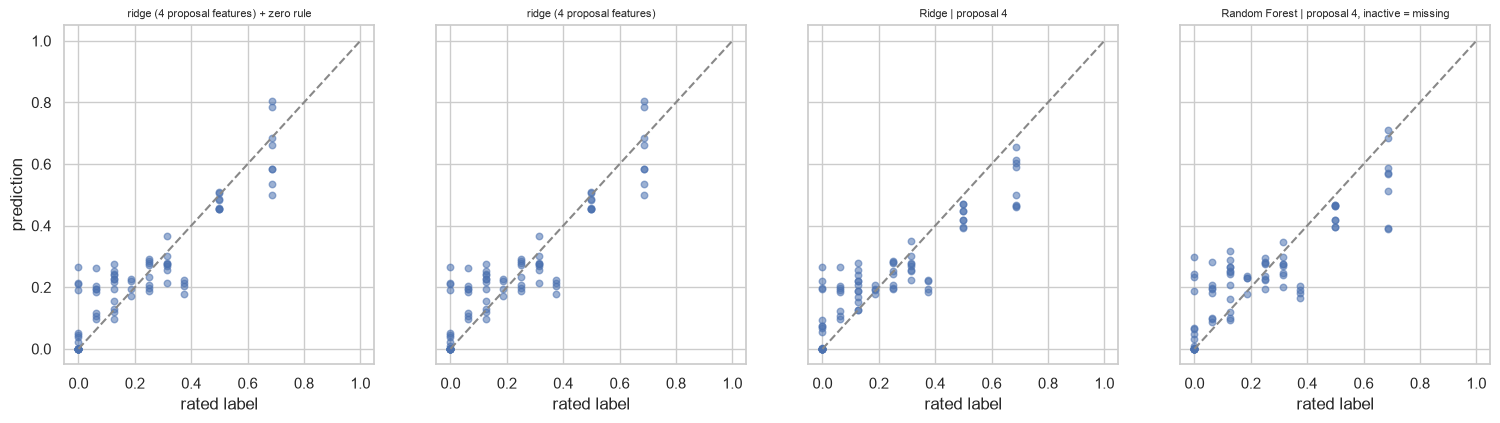

In [11]:
top = [n for n in results.index if n != "mean"][:4]
fig, axes = plt.subplots(1, len(top), figsize=(4.6 * len(top), 4.4), sharex=True, sharey=True)
for a, n in zip(np.atleast_1d(axes), top):
    g = allp[allp.name == n]
    a.scatter(g.y, g.pred, s=22, alpha=.55)
    a.plot([0, 1], [0, 1], "--", color="#888")
    a.set(title=n, xlabel="rated label")
    a.title.set_fontsize(8)
np.atleast_1d(axes)[0].set_ylabel("prediction")
plt.show()

## 10. Choose the model for the final test, and log

In [12]:
passing = decision[decision["passes 1-3"]]
if len(passing):
    pick = passing.sort_values("gain (Ridge - model)", ascending=False).iloc[0]
    outcome = {"model": pick["model"], "feature_set": pick["feature set"], "reason": "passes protocol conditions 1-3 against Ridge on the same feature set (invariants checked separately)"}
else:
    ridge_rows = results[results.index.str.startswith("Ridge |")]
    outcome = {"model": "Ridge", "feature_set": ridge_rows.index[0].split(" | ")[1], "reason": "no forest or boosting model passes protocol conditions 1-3 against Ridge"}
outcome["validation_MAE"] = round(float(results.loc[f"{outcome['model']} | {outcome['feature_set']}"].MAE), 4)
outcome["best_simple_baseline"] = {"name": best_base, "MAE": round(float(results.loc[best_base].MAE), 4)}
(F.results / "model_choice.json").write_text(json.dumps(outcome, indent=2))
for name, row in results.iterrows():
    log_run(F, "05_model_comparison", name, "validation, selection-bias-free, pooled over 20 combinations",
            {"MAE": round(row.MAE, 4), "RMSE": round(row.RMSE, 4), "pearson": round(row.Pearson, 4), "spearman": round(row.Spearman, 4),
             "bias": round(row.bias, 4), "MAE_active": round(row["MAE active"], 4)})
print(json.dumps(outcome, indent=2))

{
  "model": "Ridge",
  "feature_set": "proposal 4",
  "reason": "no forest or boosting model passes protocol conditions 1-3 against Ridge",
  "validation_MAE": 0.0751,
  "best_simple_baseline": {
    "name": "ridge (4 proposal features) + zero rule",
    "MAE": 0.0664
  }
}


## 11. Reading the results

Validation MAE, selection-bias-free, pooled over 20 combinations (always predicting the mean: 0.195):

| Model | MAE |
|---|---|
| Ridge on the 4 proposal features, **untuned** (notebook 02: alpha by leave-one-out on rated records) | **0.066** |
| Ridge on the 4 proposal features, **tuned** (this notebook) | 0.075 |
| Random Forest, 4 features, inactive = missing | 0.081 |
| Active days alone (`AWR`) | 0.085-0.087 |
| Random Forest, 4 features | 0.088 |
| Gradient Boosting, 4 features | 0.098 |
| Commits (log) | 0.103 |
| 1 - deadline share alone | 0.164-0.177 |

**1. Every fitted model is far better than guessing** (0.066-0.105 against 0.195), and **the multi-feature Ridge model clearly beats every
single-feature rule**: active days alone is 0.085, commit volume 0.103.

**2. Tuning made things worse, not better.** The untuned Ridge (0.066) beats the tuned one (0.075). Choosing settings from only three
validation groups adds noise: the search tries many label sources, weights and `alpha` values and picks one that is best on three small
groups. With 9-15 rated records per fold, the simplest fixed procedure is the most reliable.

**3. No forest or boosting model qualifies (protocol rule).** Against Ridge on the same features the gains are -0.022 to +0.006; only the
forest with inactive students marked missing wins 4 of 5 folds, and no interval excludes 0.

**4. Seeds.** Forest error moves by 0.0006-0.0014 across seeds; boosting is deterministic. Model differences are far larger.

**5. Per fold.** The untuned Ridge is the most stable (spread across folds 0.003); forests and boosting spread 0.015-0.039 (fold A, the
largest group, is hardest for them: 0.12-0.16).

**6. Ablations (means over all settings tried).** Propagated labels help here for every model (forest 0.133 -> 0.079, boosting 0.162 -> 0.076-0.080,
Ridge 0.109 -> 0.076-0.085), because the label model is accurate for Consistency. The proposal's four features beat the three-feature set for every
model (0.082-0.090 vs 0.090-0.094).

**What it means.**
- Consistency can be learned from this data: a linear model on the proposal's four features reproduces the ratings to about 0.07 (the rating
  scale is 1-5, or 0.25 per point), three times better than guessing.
- Non-linear models and heavy tuning are not justified. The model to take to the final test is the **simple Ridge on the four proposal
  features**; the tuned pipeline from notebook 04 is not used.

Saved: `training/results/model_choice.json`, `comparison_tuned_predictions.csv`.